In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Student Social Media And Mental Health Impact.csv")

In [3]:
df.shape

(5000, 13)

In [4]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [5]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [6]:
df.duplicated().value_counts()

False    4998
True        2
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [8]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


## EDA 

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

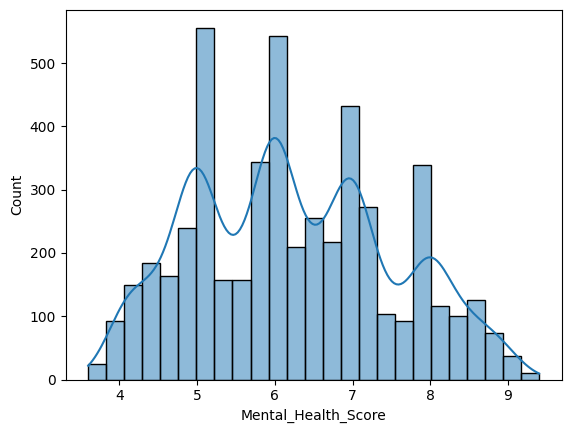

In [9]:
sns.histplot(df['Mental_Health_Score'],kde=True)

<Axes: >

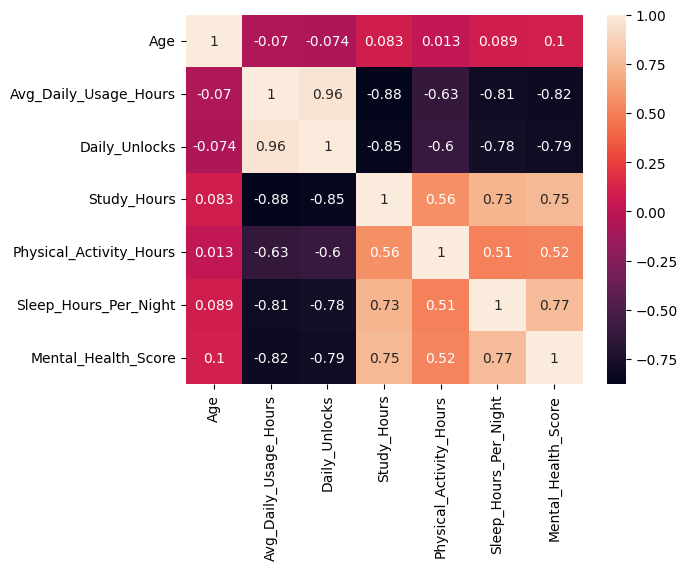

In [10]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [11]:
df.corr(numeric_only=True)

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
Age,1.000000,-0.070092,-0.074488,0.083109,0.012984,0.088681,0.100785
Avg_Daily_Usage_Hours,-0.070092,1.000000,0.960187,-0.878645,-0.625707,-0.808388,-0.816453
Daily_Unlocks,-0.074488,0.960187,1.000000,-0.853397,-0.602828,-0.781823,-0.790851
Study_Hours,0.083109,-0.878645,-0.853397,1.000000,0.560532,0.730136,0.752626
Physical_Activity_Hours,0.012984,-0.625707,-0.602828,0.560532,1.000000,0.507851,0.521374
Sleep_Hours_Per_Night,0.088681,-0.808388,-0.781823,0.730136,0.507851,1.000000,0.766430
Mental_Health_Score,0.100785,-0.816453,-0.790851,0.752626,0.521374,0.766430,1.000000


<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

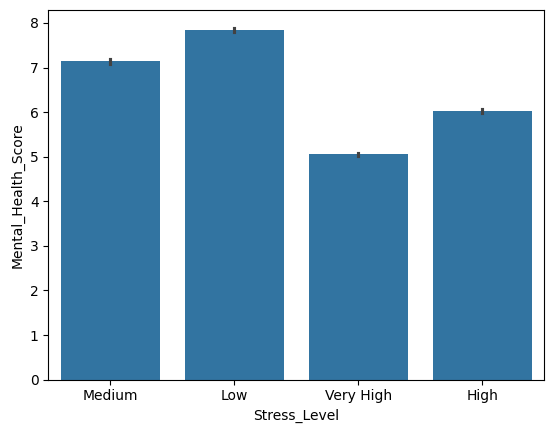

In [12]:
sns.barplot(data=df,x='Stress_Level',y='Mental_Health_Score')

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

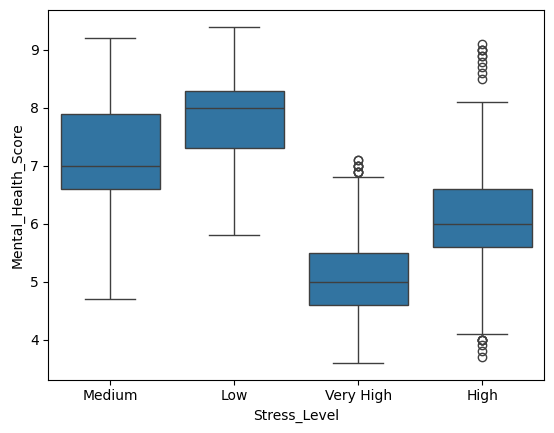

In [13]:
sns.boxplot(data=df,x='Stress_Level',y='Mental_Health_Score')

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

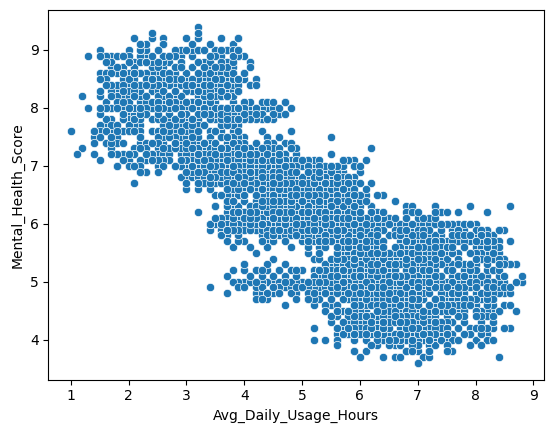

In [14]:
sns.scatterplot(data=df,x='Avg_Daily_Usage_Hours',y='Mental_Health_Score')

In [15]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

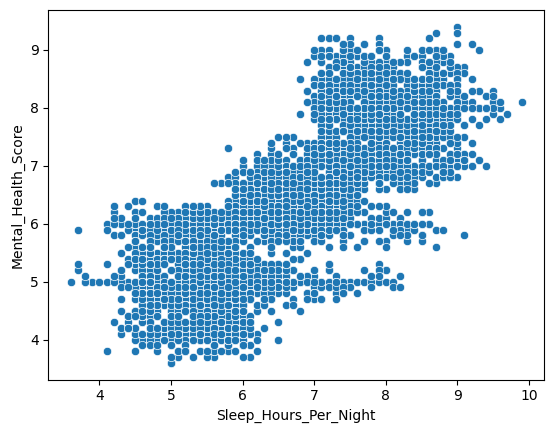

In [16]:
sns.scatterplot(data=df,x='Sleep_Hours_Per_Night',y='Mental_Health_Score')

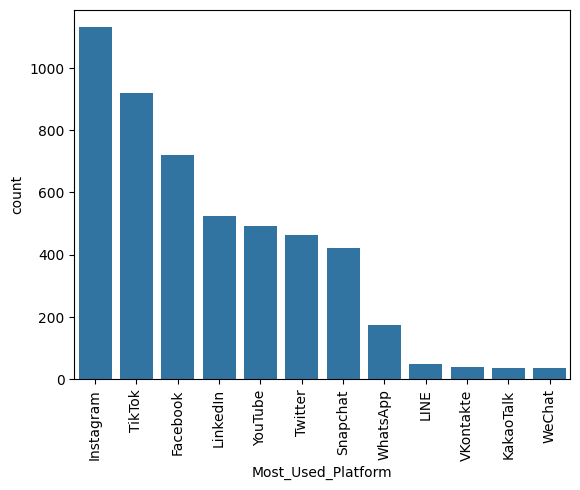

In [17]:
sns.countplot(data=df , x = 'Most_Used_Platform',order=df['Most_Used_Platform'].value_counts().index)
plt.xticks(rotation=90)
plt.show()

In [18]:
numerical_cols = df.select_dtypes(include='number')
Q1 = numerical_cols.quantile(0.25)
Q3 = numerical_cols.quantile(0.75)
IQR = Q3-Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

outlier = (numerical_cols < lower_bound) | (numerical_cols > upper_bound)

In [19]:
outlier.sum()

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64

## Data Cleaning

In [20]:
df.describe(include='all')

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
count,5000.00000,5000,5000,5000,5000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000
unique,NaN,2,111,3,12,4,NaN,NaN,NaN,NaN,NaN,4,NaN
top,NaN,Male,Other,Undergraduate,Instagram,Entertainment,NaN,NaN,NaN,NaN,NaN,Very High,NaN
freq,NaN,2635,1880,3632,1130,2552,NaN,NaN,NaN,NaN,NaN,1621,NaN
mean,20.82180,NaN,NaN,NaN,NaN,NaN,5.078460,171.452600,3.008420,1.751000,6.634580,NaN,6.230980
std,1.73662,NaN,NaN,NaN,NaN,NaN,1.653913,42.858254,1.637018,0.668398,1.221391,NaN,1.278701
min,18.00000,NaN,NaN,NaN,NaN,NaN,1.000000,62.000000,0.300000,-0.400000,3.600000,NaN,3.600000
25%,19.00000,NaN,NaN,NaN,NaN,NaN,3.800000,140.000000,1.500000,1.300000,5.600000,NaN,5.100000
50%,21.00000,NaN,NaN,NaN,NaN,NaN,5.000000,171.000000,2.800000,1.700000,6.600000,NaN,6.100000
75%,22.00000,NaN,NaN,NaN,NaN,NaN,6.300000,204.000000,4.200000,2.200000,7.500000,NaN,7.100000


In [21]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df['Physical_Activity_Hours'].clip(lower=0,inplace=True) # Its is used to replace all the negative value to any lower value for particular column

C:\Users\Harshgupta\AppData\Local\Temp\ipykernel_18636\1960657499.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Physical_Activity_Hours'].clip(lower=0,inplace=True) # Its is used to replace all the negative value to any lower value for particular column


In [22]:
df.describe() ### Now there is not any negative value

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [23]:
df.skew(numeric_only='True')
## Near to zero --> Centralized
## greater than zero (Towards Positive) --> Right Skew
## less than zero (Towards Negative) --> Left Skew

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

##### How we fix skewness --> Applying Log Transformation / Standard Scalar

### Feature Engg

In [56]:
top_countries = df['Country'].value_counts().index[:10].to_list()
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

In [25]:
def feature_countries(country):
    if country in top_countries:
        return country
    else :
        return 'Other'

In [26]:
df['Grouped_Countries'] = df['Country'].apply(feature_countries)

In [27]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Grouped_Countries
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,Other
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,Other
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,Canada
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,Other
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,Other


In [28]:
df['Country'].unique()

array(['Other', 'Canada', 'USA', 'India', 'Australia', 'UK', 'Germany',
       'Bangladesh', 'Brazil', 'Japan', 'South Korea', 'France', 'Spain',
       'Italy', 'Mexico', 'Russia', 'China', 'Sweden', 'Norway',
       'Denmark', 'Netherlands', 'Belgium', 'Switzerland', 'Austria',
       'Portugal', 'Greece', 'Ireland', 'New Zealand', 'Singapore',
       'Malaysia', 'Thailand', 'Vietnam', 'Philippines', 'Indonesia',
       'Taiwan', 'Hong Kong', 'Turkey', 'Israel', 'UAE', 'Egypt',
       'Morocco', 'South Africa', 'Nigeria', 'Kenya', 'Ghana',
       'Argentina', 'Chile', 'Colombia', 'Peru', 'Venezuela', 'Ecuador',
       'Uruguay', 'Paraguay', 'Bolivia', 'Costa Rica', 'Panama',
       'Jamaica', 'Trinidad', 'Bahamas', 'Iceland', 'Finland', 'Poland',
       'Romania', 'Hungary', 'Czech Republic', 'Slovakia', 'Croatia',
       'Serbia', 'Slovenia', 'Bulgaria', 'Estonia', 'Latvia', 'Lithuania',
       'Ukraine', 'Moldova', 'Belarus', 'Kazakhstan', 'Uzbekistan',
       'Kyrgyzstan', 'Tajiki

In [29]:
from sklearn.model_selection import train_test_split
skew_col = ['Study_Hours']
other_numerical_cols = ['Age','Avg_Daily_Usage_Hours','Daily_Unlocks','Physical_Activity_Hours','Sleep_Hours_Per_Night']
ordinal_col = ['Stress_Level']
normal_col = ['Gender','Academic_Level','Most_Used_Platform','Purpose_Of_Use','Grouped_Countries']

feature_cols = skew_col + other_numerical_cols + ordinal_col + normal_col
X = df[feature_cols]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [30]:
X

,Study_Hours,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Gender,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Grouped_Countries
0,4.5,21,4.0,134,2.2,6.7,Medium,Male,Undergraduate,Facebook,Networking,Other
1,7.0,23,1.6,73,2.4,8.6,Low,Female,Graduate,LinkedIn,Education,Other
2,4.0,22,4.6,166,1.8,6.7,Medium,Male,Undergraduate,Instagram,Entertainment,Canada
3,1.0,18,7.0,220,1.7,5.4,Very High,Male,High School,Snapchat,Entertainment,Other
4,1.0,24,7.5,237,1.1,5.0,Very High,Female,Graduate,Facebook,Networking,Other
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,6.1,18,1.9,89,2.2,7.9,Low,Female,High School,YouTube,Education,Other
4996,2.3,18,6.6,216,1.8,6.0,Very High,Female,High School,YouTube,Education,Other
4997,5.4,19,3.8,151,1.4,7.5,Medium,Female,Undergraduate,LinkedIn,Education,India
4998,4.0,18,3.8,119,1.5,6.4,Medium,Male,High School,Instagram,Entertainment,Other


In [31]:
y

0       6.8
1       7.6
2       7.0
3       5.3
4       4.4
       ... 
4995    7.9
4996    4.7
4997    7.0
4998    6.7
4999    6.1
Name: Mental_Health_Score, Length: 4998, dtype: float64

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer , StandardScaler

In [33]:
skew_pipeline = Pipeline(steps =
                        [('LogTransformer',FunctionTransformer(np.log1p)),
                        ('scale',StandardScaler())
                        ])

plain_numerical_pipeline = Pipeline(steps=
                                   [('scale',StandardScaler())
                                   ])
ordinal_pipeline = Pipeline(steps = 
                           [('encode',OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
                            ])
nomial_pipeline = Pipeline(steps = 
                          [('encode',OneHotEncoder(handle_unknown='ignore'))])

In [34]:
from sklearn.compose import ColumnTransformer

In [35]:
preprocessor = ColumnTransformer(
        transformers=[
            ('skewness',skew_pipeline,skew_col),
            ('numerical_one',plain_numerical_pipeline,other_numerical_cols),
            ('ordinal',ordinal_pipeline,ordinal_col),
            ('nomial',nomial_pipeline,normal_col)
        ]
)

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [37]:
lr_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',LinearRegression())
])

In [38]:
lr_pipeline.fit(X_train,y_train)
lr_pred = lr_pipeline.predict(X_test)
lr_pred_train = lr_pipeline.predict(X_train)
print("The R2 score is for testing",r2_score(y_test,lr_pred))
print("The R2 score is for training",r2_score(y_train,lr_pred_train))
print("The mean absoulte error is",mean_absolute_error(y_test,lr_pred))
print("The mean squared error is",mean_squared_error(y_test,lr_pred))

The R2 score is for testing 0.7397944617433021
The R2 score is for training 0.7236771199387539
The mean absoulte error is 0.5361775634720182
The mean squared error is 0.45701905273487986


In [39]:
rf_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(random_state=42))
])

In [40]:
rf_pipeline.fit(X_train,y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_pred_train = rf_pipeline.predict(X_train)
print("R2 score for test is",r2_score(y_test,rf_pred))
print("R2 score for train is",r2_score(y_train,rf_pred_train))
print("The mean absoulte error is",mean_absolute_error(y_test,rf_pred))
print("The mean squared error is",mean_squared_error(y_test,rf_pred))

R2 score for test is 0.8775888638668996
R2 score for train is 0.9808287942404612
The mean absoulte error is 0.34722113333333343
The mean squared error is 0.21500011819333337


In [41]:
para_grid = {
    'model__n_estimators':[75,150,250,300],
    'model__max_depth':[5,10,15,20],
    'model__min_samples_split':[2,8,4],
    'model__min_samples_leaf':[1,2,4]
}

In [42]:
from sklearn.model_selection import RandomizedSearchCV

In [43]:
rscv = RandomizedSearchCV(estimator=rf_pipeline,
                          param_distributions=para_grid,
                          n_iter=10,
                          cv=5,
                          scoring='r2',
                          random_state=42,
                          n_jobs=-1)

In [44]:
rscv

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 8, ...], 'model__n_estimators': [75, 150, ...]}"
,n_iter,10
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [45]:
rscv.fit(X_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 8, ...], 'model__n_estimators': [75, 150, ...]}"
,n_iter,10
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [46]:
rscv.best_params_

{'model__n_estimators': 150,
 'model__min_samples_split': 4,
 'model__min_samples_leaf': 1,
 'model__max_depth': 20}

In [47]:
rscv.best_score_

np.float64(0.850312306877018)

In [48]:
rf_best_pipeline = rscv.best_estimator_
rf_pred = rf_best_pipeline.predict(X_test)
rf_pred_train = rf_best_pipeline.predict(X_train)

print("r2 score",r2_score(y_test,rf_pred))
print("r2 score train",r2_score(y_train,rf_pred_train))

r2 score 0.8753423189881421
r2 score train 0.974958194200215


In [49]:
rscv.best_estimator_

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('skewness', ...), ('numerical_one', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Download the model

In [50]:
import joblib
joblib.dump(rf_best_pipeline,'Model.pkl')

['Model.pkl']

In [51]:
print(rf_best_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skewness',
                                                  Pipeline(steps=[('LogTransformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('numerical_one',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                            

In [54]:
df.columns.tolist()

['Age',
 'Gender',
 'Country',
 'Academic_Level',
 'Most_Used_Platform',
 'Purpose_Of_Use',
 'Avg_Daily_Usage_Hours',
 'Daily_Unlocks',
 'Study_Hours',
 'Physical_Activity_Hours',
 'Sleep_Hours_Per_Night',
 'Stress_Level',
 'Mental_Health_Score',
 'Grouped_Countries']

In [55]:
df.dtypes

Age                          int64
Gender                      object
Country                     object
Academic_Level              object
Most_Used_Platform          object
Purpose_Of_Use              object
Avg_Daily_Usage_Hours      float64
Daily_Unlocks                int64
Study_Hours                float64
Physical_Activity_Hours    float64
Sleep_Hours_Per_Night      float64
Stress_Level                object
Mental_Health_Score        float64
Grouped_Countries           object
dtype: object

In [60]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)